<a href="https://colab.research.google.com/github/obeneitonem/income-prediction-ml/blob/main/income_prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Clasificación binaria de ingresos con técnicas de Aprendizaje Automático**


---



**Grupo 19**


---



Integrante: Felipe Borre

*  Mail: feliborre1@gmail.com

Integrante: Olivia Beneitone Marty

- Mail: obeneitone@gmail.com

Integrante: Marcos Benson

- Mail: marcosbenson21@gmail.com



Link al dataset original: https://archive.ics.uci.edu/dataset/2/adult



**Objetivos y Logros**


---

En el primer entregable, realizamos varios gráficos para analizar la relación de las variables con el Target. Concluimos que aunque las clases estén desbalanceadas (<=50K= 37155, >50K= 11687) existe bastante potencial para realizar una clasificación binaria. El objetivo de esta entrega es desarrollar modelos progresivamente más complejos mientras mejoran sus métricas. Tenemos la intención de prestar especial atención a la elección de hiperparámetros, a la interpretación de los resultados y la comparación entre los distintos modelos para buscar el que mejor clasifique los ingresos.


<div style="page-break-before: always;"></div>

<div style="page-break-before: always;"></div>

<div style="page-break-before: always;"></div>

<div style="page-break-before: always;"></div>

<div style="page-break-before: always;"></div>

<div style="page-break-before: always;"></div>

<div style="page-break-before: always;"></div>

<div style="page-break-before: always;"></div>

**Benchmark**


---

Como modelo de referencia decidimos crear un Dummy Classifier, este clasificador predice en todas las instancias un sueldo igual o menor a $50.000 USD.

El desmpeño del modelo fue medido en sus métricas:
- Acuraccy: 0,76
- Recall: 0,76
- Precisión: 0,58
- F1-score: 0,66  


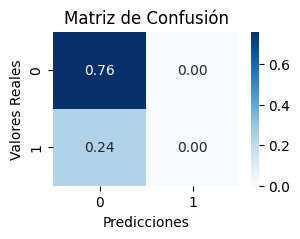

Interpretación


---


El Dummy Classifier predice siempre la clase más frecuente, en este caso, ≤50K (por eso en la matriz de confusión no hay verdaderos positivos ni falsos positivos). Como la gran mayoría de las instancias pertenecen a esta clase, las predicciones resultan en muchos casos correctas, lo que hace que el accuracy y recall sean altos.
Para ser un modelo sencillo, el desempeño no es tan malo, especialmente en accuracy y recall, sin embargo, su precisión es bastante baja, por lo que esperamos ver en los próximos modelos un aumento en todos los aspectos pero especialmente en precisión.

<div style="page-break-before: always;"></div>

<div style="page-break-before: always;"></div>

<div style="page-break-before: always;"></div>

<div style="page-break-before: always;"></div>

<div style="page-break-before: always;"></div>

<div style="page-break-before: always;"></div>

**Modelo de Árbol de decisión**

---

Para poder superar el Benchmark decidimos entrenar un DecisionTreeClassifier (árbol de decisión) seleccionando únicamente dos variables. Para poder entrenar el mejor árbol probamos distintas combinaciones de atributos, evaluando su desempeño mediante métricas de Accuracy, precisión, F-score y Recall. Tras este análisis elegimos 'hours-per-week' (horas de trabajo por semana) y 'Education-num' (Años de educación).

Como preprocesamiento decidimos separar los datos usando Train_test_split reservando el 30% de los datos para prueba.


Profundidad


---

Para decidir el hiperparámetro Max_depth realizamos el siguiente gráfico en el que se ve la precisión del árbol según profundidad en entrenamiento y prueba. Elegimos Max_depth= 4 ya que la precisión en train y test aumentan y se mantienen bastante cercanas.

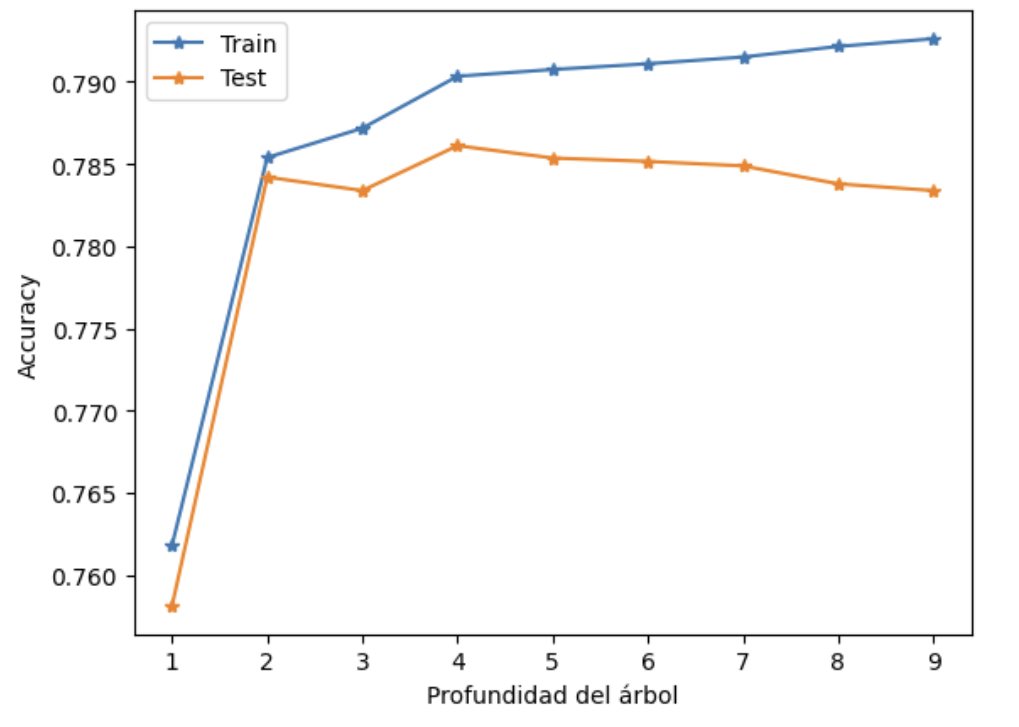

<img scr="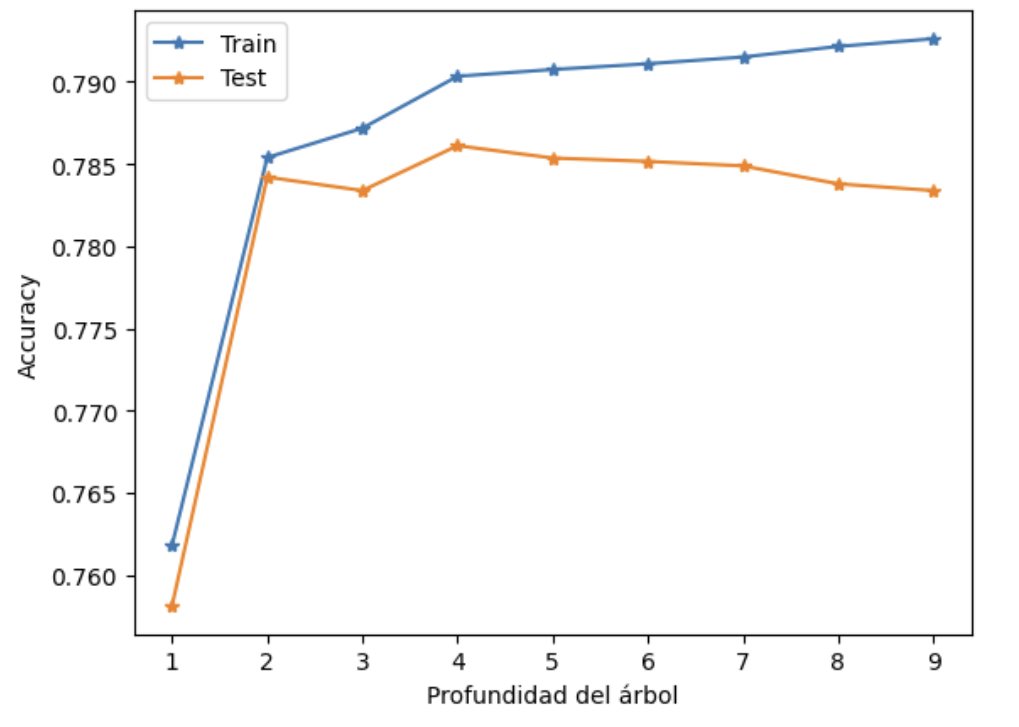" width="700">

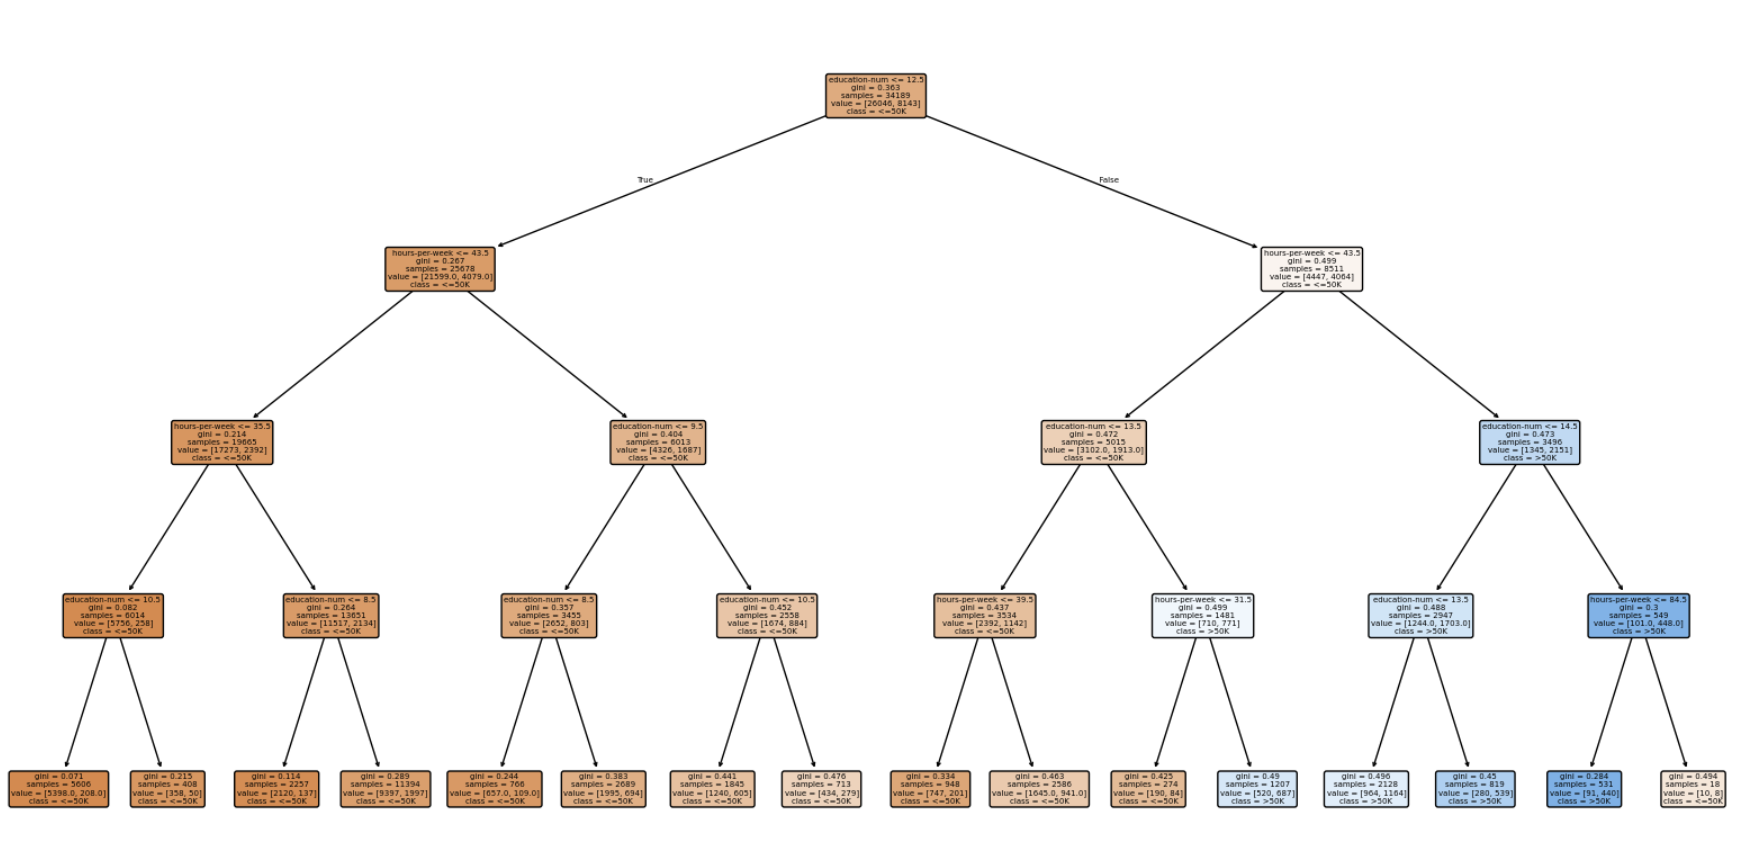


Frontera de decisión


---
De este gráfico podemos deducir que la variable 'Education-Num' es muy significativa en la predicción de los ingresos. En general las personas que tienen entre 12 a 16 años de educación tienen más probabilidades de tener ingresos >50K independientemente de las horas trabajadas.
Sin embargo, se puede ver que hay errores en la clasificación, lo que nos hace pensar que hay otras variables influyentes en el ingreso que no estamos considerando.




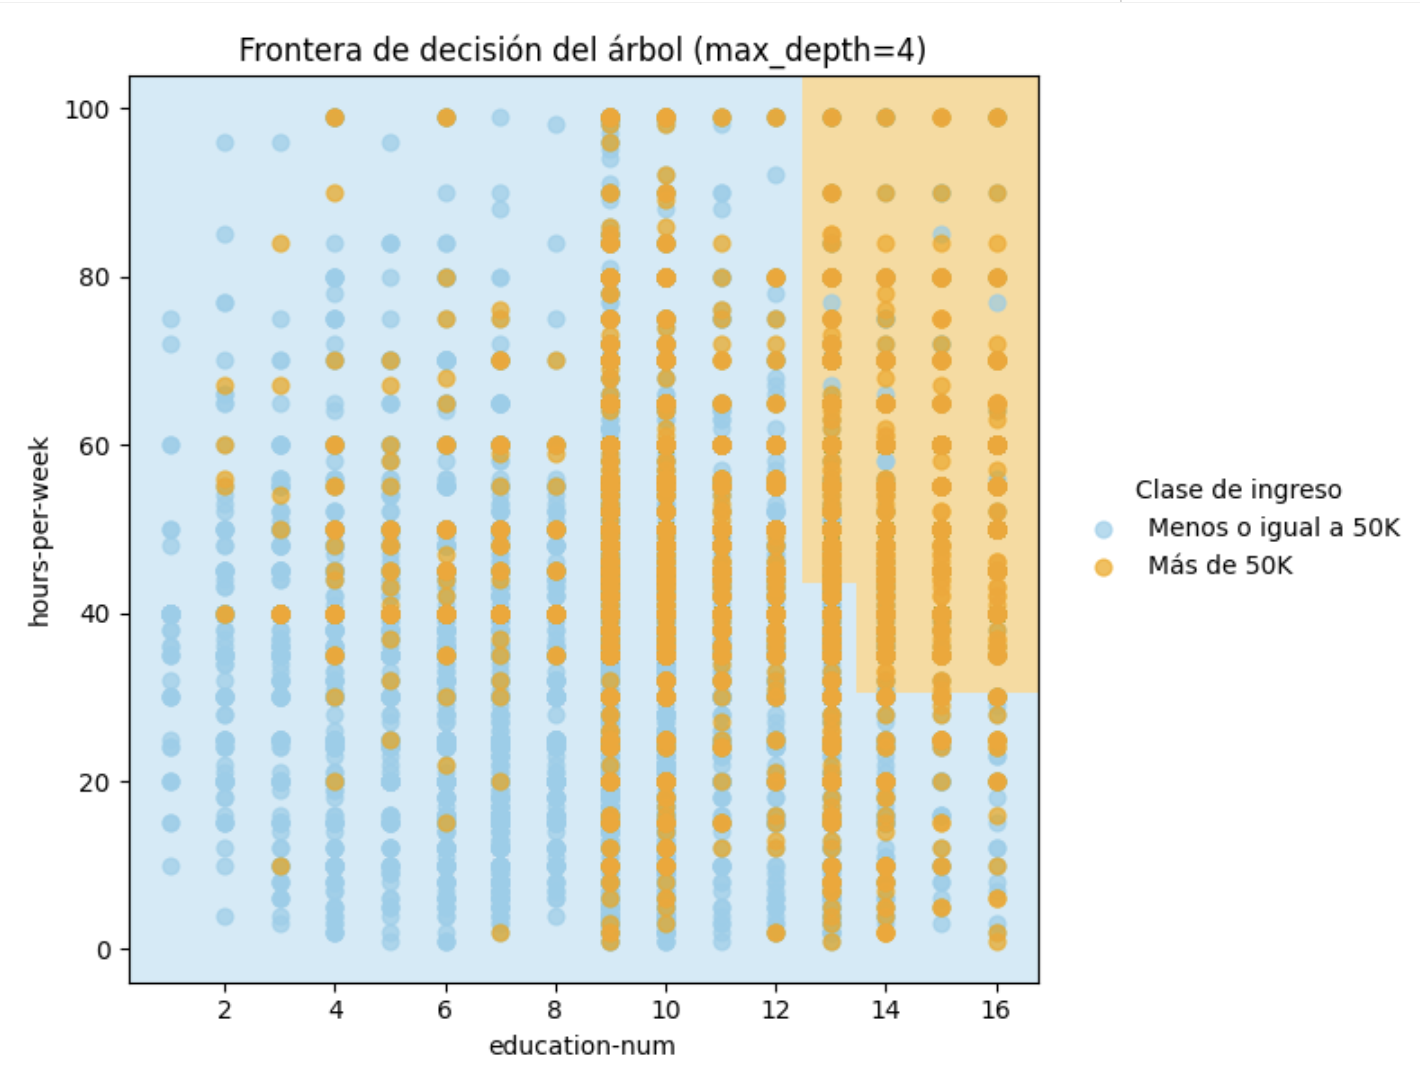



<div style="page-break-before: always;"></div>

Desempeño


---


Su desempeño fue medido en sus métricas:
- Acuraccy: 0.786
- Recall: 0.79
- Precision: 0.76
- F1-score: 0.76

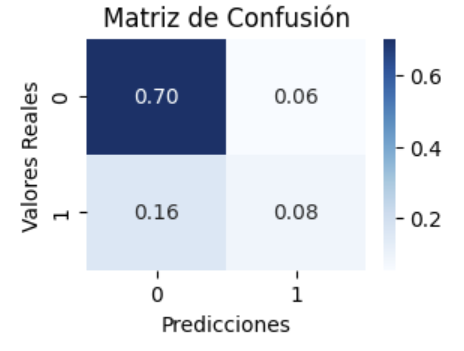

Con estas métricas sacamos las siguientes conclusiones del modelo:
- Predice correctamente el ingreso el 78,6% de las veces (Accuracy)
- De todos las instancias reales de >50K detecta correctamente el 79% (Recall)
- De todas las predicciones de >50K precide correctamente el 76% (Precisión)

Estos resultados muestran que el árbol de decisión supera ampliamente al DummyClassifier (Benchmark), especialmente en el aspecto de precisión, que subió de 0.58 a 0.76, esto representa un aumento de 32% con respecto al benchmark.

<div style="page-break-before: always;"></div>

<div style="page-break-before: always;"></div>

<div style="page-break-before: always;"></div>

<div style="page-break-before: always;"></div>

<div style="page-break-before: always;"></div>

<div style="page-break-before: always;"></div>

<div style="page-break-before: always;"></div>

Curva ROC


---
En el siguiente gráfico podemos ver la curva ROC, es decir la relación entre FPR y TPR del modelo para distintos umbrales. La AUC (área bajo la curva) es de 0.76 por lo que el modelo tiene 76% de probabilidad de predecir bien la clase de ingreso de un caso elegido al azar.

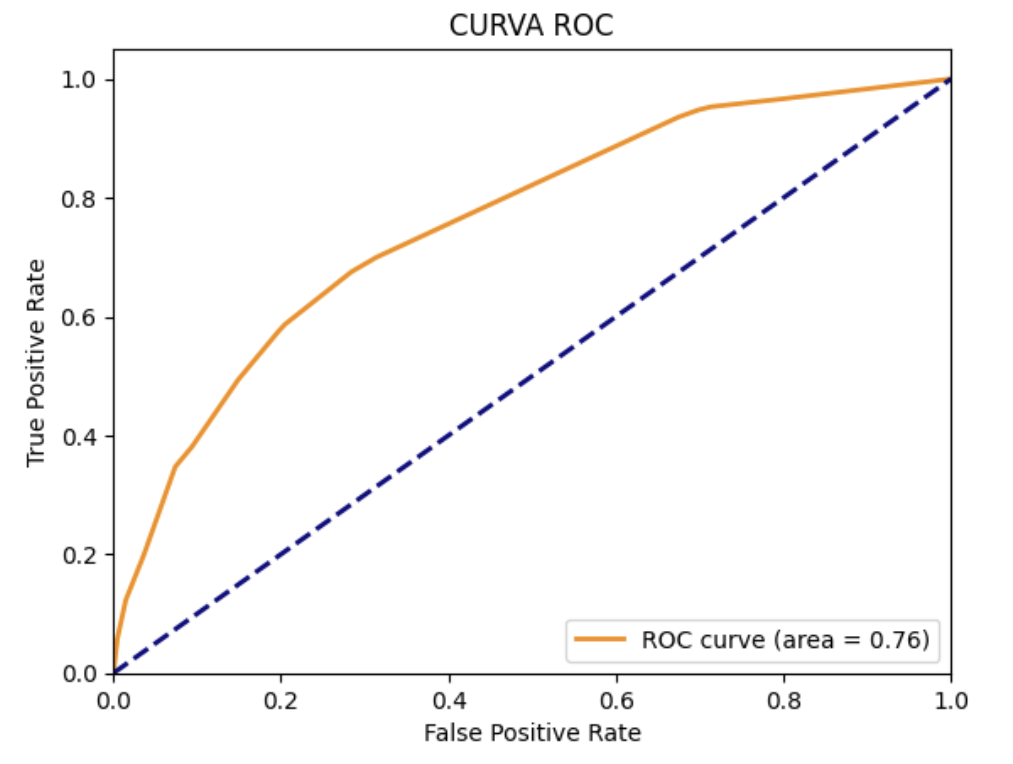

<div style="page-break-before: always;"></div>

<div style="page-break-before: always;"></div>

<div style="page-break-before: always;"></div>

<div style="page-break-before: always;"></div>

<div style="page-break-before: always;"></div>

<div style="page-break-before: always;"></div>

<div style="page-break-before: always;"></div>

<div style="page-break-before: always;"></div>

**Modelo Random Forest**


---
Como segundo modelo elegimos el Random Forest, en este caso, usamos todas las variables del dataset. En el preprocesado, se aplicó OneHotEncoding a las variables categóricas. En los hiperparámetros, se usó min_samples_split = 20 y n_estimators = 150, porque estos valores nos dan un buen equilibrio entre peso computacional y buen desempeño en las métricas.

Su desempeño fue medido en sus métricas:
- Acuraccy: 0,86
- Recall: 0,86
- Precision: 0,86
- F1-score: 0,86
- Cross-validation scores: [0.86375269 0.86262668 0.8721335  0.86240786 0.86476249]
- Valor promedio en validación cruzada (5 Folds): 0,865

Estas métricas representan una notable mejora con respecto al árbol de decisión. Este resultado es esperable teniendo en cuenta que el random forest es un modelo de ensamble que usa una combinación de árboles de decisión.


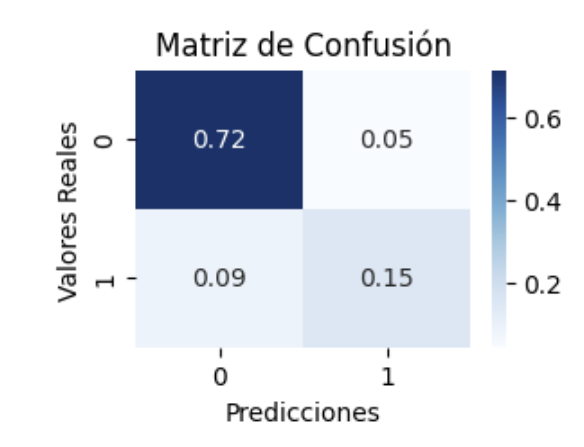

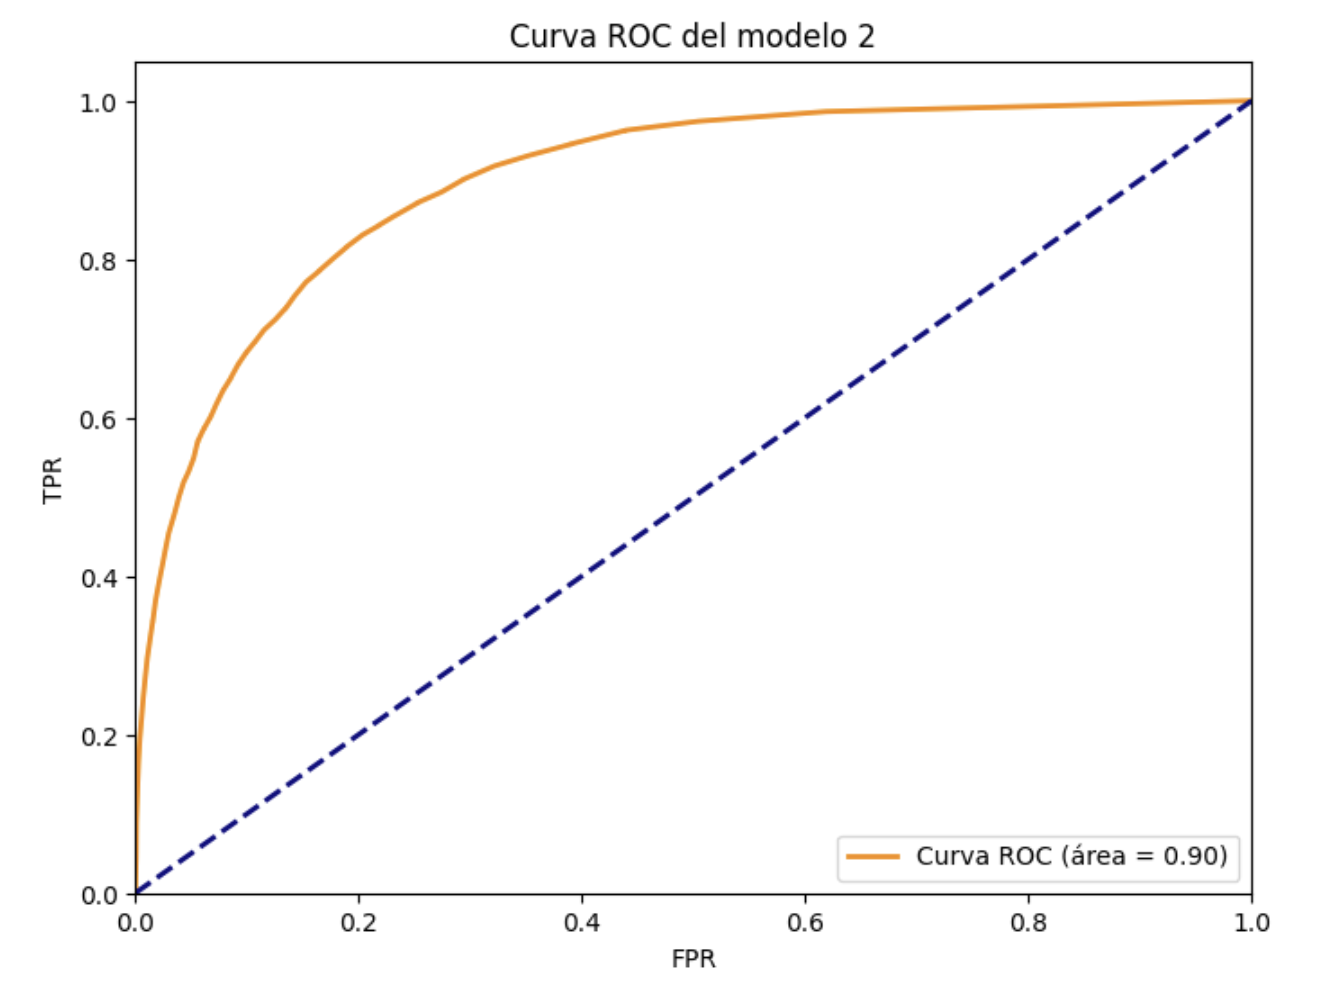

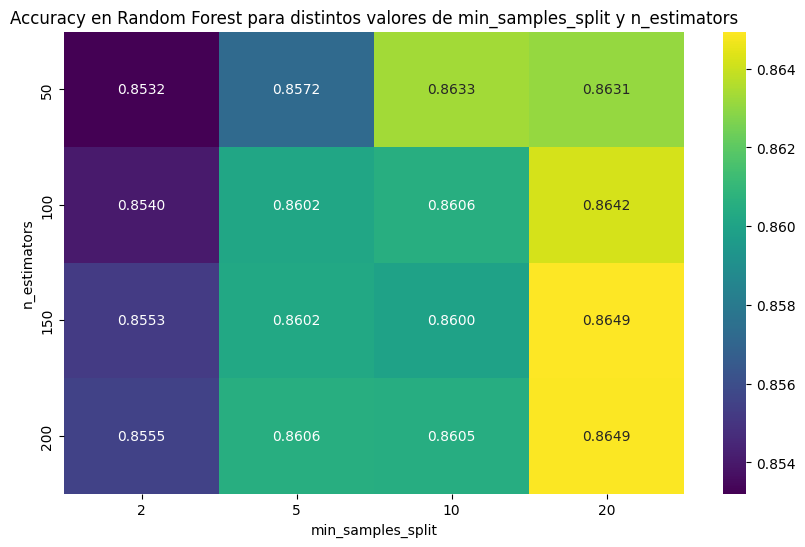

En el gráfico anterior se aprecia como con 150 estimadores y un valor de 20 en min_samples_split conseguimos maximizar la exactitud de las predicciones del modelo.

<div style="page-break-before: always;"></div>

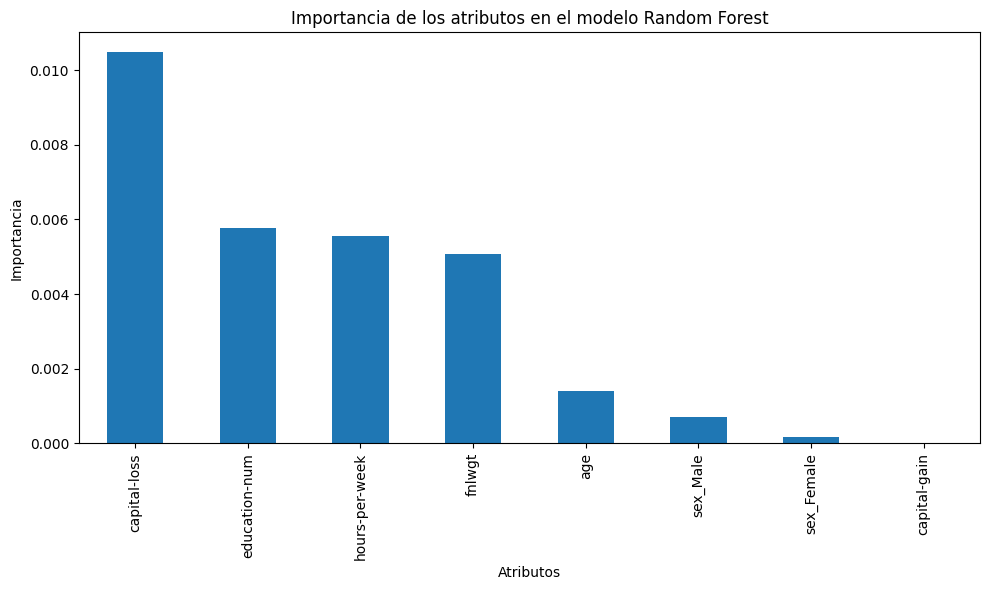

En el gráfico anterior se aprecia la importancia de algunas variables, lógicamente no se pueden incluir todas ya que usamos dummies en este modelo, por lo que decidimos visualizar las que consideramos que tienen más significancia. Se puede apreciar que la más relevante es capital-loss (Pérdida de capital) seguida de las horas de trabajo por semana y los años de educación. A diferencia de lo que creíamos, el sexo resultó no ser una variable tan relevante.

Para obtener esta información usamos la función *feature_importances_* de scikit-learn, esta función se basa en el MDI (disminución promedio de impureza) en cada árbol para cada variable, un mayor MDI implica más importancia.

<div style="page-break-before: always;"></div>

<div style="page-break-before: always;"></div>

<div style="page-break-before: always;"></div>

<div style="page-break-before: always;"></div>

<div style="page-break-before: always;"></div>

<div style="page-break-before: always;"></div>


# **Comparación de modelos**

---



| Modelo | Accuracy| Precision | Recall | F1-Score |
|-----------|--------|-------------|-------------| ------------|
|Benchmark (Dummy Classifier)   |  0,76   |    0,58      | 0,76 | 0,66
| Modelo 1 (Árbol de decisión)|   0,78  |    0,76       | 0,79 | 0,76
| Modelo 2 (Random Forest)|   0,86   |  0,86           | 0,86 | 0,86


Comparando los tres modelos podemos concluir que los últimos dos mejoran en gran medida sobre el Benchmark. El dummy Classfier predice siempre la clase más frecuente por lo que su Accuracy y Recall son bastante altos, pero por la precisión nos damos cuenta que no logra detectar bien las instancias de >50K.
El árbol de decisión, con únicamente dos atributos ('hours-per-week' y 'Education-num') mejora todas las métricas, en especial la precisión en un 32%, lo que significa que detecta en un 78% la clase de mayor ingreso.
El último modelo, de Random Forest, supera ampliamente al árbol de decisión.


  Sabiendo que Random Forest utiliza múltiples arboles, esperábamos una clara mejoría en comparación al árbol de decisión planteado anteriormente, la cual se observa en las métricas.
  
  Este rendimiento, superior al primer modelo y al benchmark, nos hace pensar que sería la mejor opción para una fase operativa.
Dicho esto, si el contexto nos exige un modelo que sea más interpretable por algún motivo, tendríamos que inclinarnos hacia el árbol de decisión, a pesar de que su rendimiento no sea el mejor.

# **Pasos a seguir**


---

Para continuar el trabajo, se podría experimentar con otros modelos, por ejemplo, XGBoost. También se podría realizar un GridSearch en los hiperparámetros del RandomForest para encontrar con más exactitud los mejores valores. Además identificamos que el RandomForest tiene niveles altos de varianza, por lo que podríamos buscar estrategias para reducirla.

Otra idea es crear modelos intermedios entre el árbol de decisión y el Random Forest ya que ayudaría a analizar el impacto de ir agregando nuevas variables. También sería útil para encontrar el equilibrio entre complejidad e interpretabilidad, debido a que el árbol es muy fácil de interpretar pero menos preciso, mientras que el Random forest es tan preciso como complejo. Encontrar un modelo intermedio con estas características optimizaría también memoria y tiempo (ya que el Random Forest es muy costoso computacionalmente).